In [2]:
#requirements
import pandas as pd
import numpy as np
import os, re, sys
import pickle

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MultiLabelBinarizer
from pathlib import Path


PROJECT_ROOT = Path(os.getcwd()).parent
print(f"Project root directory: {str(PROJECT_ROOT)}")
BIG_DATA     = PROJECT_ROOT / "big_data"
DATA_DIR     = PROJECT_ROOT / "data"


Project root directory: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers


In [3]:
in_pkl = BIG_DATA / "baseline" / "pickle" / "raw_articles.pkl"
print(f"Input will be loaded from: {in_pkl}")
if not in_pkl.exists():
    print(f"Error: Input file {in_pkl} does not exist.")
    raise FileNotFoundError(f"Input file {in_pkl} does not exist.") 


Input will be loaded from: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\big_data\baseline\pickle\raw_articles.pkl


In [4]:
keywords = set()

df = pd.read_pickle(in_pkl)
print(f"Data loaded successfully. Number of records: {len(df)}")
df.head(5)


Data loaded successfully. Number of records: 41449


,filename,pmcid,doi,journal,year,authors,title,keywords,abstract,introduction,methods,results,discussion,conclusion,tables,metadata_junk
0,PMC3000446.xml,PMC3000446,10.1136/bjo.2010.182402,Br J Ophthalmol The British Journal of Ophthal...,2010,Crosby Michelle B; Yang Hua; Gao Weiqing; Zhan...,Serum vascular endothelial growth factor (VEGF...,Pathology; neoplasia,A preliminary animal study was performed to de...,Uveal melanoma is the most common primary mali...,"B16LS9 cells (courtesy of D. Rusciano, Friedri...",Serum VEGF levels rose after inoculation of C5...,We have shown that serum VEGF levels rise over...,,,
1,PMC3000522.xml,PMC3000522,10.1016/j.plefa.2010.07.006,Prostaglandins Leukot Essent Fatty Acids Prost...,2010,Slater-Jefferies Joanne L.; Hoile Samuel P.; L...,Effect of sex and dietary fat intake on the fa...,Fatty acids; Heart; Phophospholipids; Rat; Sex...,Variations in the fatty acid composition of li...,The fatty acid composition of membranes is an ...,Diets were from Special Diets Services (Witham...,Analysis of the fatty acid compositions of ind...,The findings of this study show that feeding d...,,Pregnancy Lactation Post-weaning diet Diets Di...,
2,PMC3000561.xml,PMC3000561,10.1093/cercor/bhq050,"Cereb Cortex Cerebral Cortex (New York, NY)",2011,Yue Xiaomin; Cassidy Brittany S.; Devaney Kath...,Lower-Level Stimulus Features Strongly Influen...,"CMF; FFA; V1; contrast gain, face recognition",An intriguing region of human visual cortex (t...,"Previous fMRI ( Empirically, this face selecti...",The face/head 3D meshes were generated by Face...,"In response to variations in each parameter, s...","In many reports, face selectivity is the defin...",,,\n[funding]: National Institutes of Health ( E...
3,PMC3000565.xml,PMC3000565,10.1093/cercor/bhq063,"Cereb Cortex Cerebral Cortex (New York, NY)",2011,Kherif Ferath; Josse Goulven; Price Cathy J.,Automatic Top-Down Processing Explains Common ...,language; priming; repetition suppression; vis...,Previous studies have demonstrated that a regi...,Neuroimaging studies have shown that the visua...,The study was approved by the National hospita...,Mean accuracy for picture naming was 96.9% in ...,"In this study, we used an fMRI adaptation tech...",,Posterior LvOT Anterior LvOT Coordinates score...,\n[funding]: Wellcome Trust (WT082420) and the...
4,PMC3000568.xml,PMC3000568,10.1093/cercor/bhq072,"Cereb Cortex Cerebral Cortex (New York, NY)",2011,Fujiwara Keishi; Akao Teppei; Kurkin Sergei; F...,Activity of Pursuit-Related Neurons in Medial ...,MST; coordinate; monkey; optic flow; preferred...,Recent studies have shown that rhesus macaques...,We asked whether the discharge coding smooth p...,Two Japanese monkeys (Y and S Macaca fuscata 5...,We tested the effect of static whole-body roll...,Our results were collected from 51 MSTd neuron...,,Smooth pursuit (no background) Optic flow Type...,\n[funding]: Grant-in-Aid for Scientific Resea...


In [5]:

print(f"Unique journals: {df['journal'].nunique()}")
print(df["journal"].unique())


Unique journals: 1402
<ArrowStringArray>
[                                            'Br J Ophthalmol The British Journal of Ophthalmology',
 'Prostaglandins Leukot Essent Fatty Acids Prostaglandins, Leukotrienes, and Essential Fatty Acids',
                                                      'Cereb Cortex Cerebral Cortex (New York, NY)',
                                                         'Korean J Pain The Korean Journal of Pain',
                                                    'Genome Biol Evol Genome Biology and Evolution',
                        'Atten Defic Hyperact Disord Attention Deficit and Hyperactivity Disorders',
                                                  'J Biol Chem The Journal of Biological Chemistry',
                                                                    'Horm Cancer Hormones & Cancer',
                                                               'Eur Heart J European Heart Journal',
                                                  

In [6]:

keywords = dict()
MIN_FREQ = 10

for index, row in df.iterrows():
        filename = row['filename']
        keywords_list = row['keywords'].lower().split(";")
        for keyword in keywords_list:
            keyword = keyword.strip()            
            if keywords.get(keyword) is None:
                keywords[keyword] = list()            
            keywords[keyword].append(filename)
# sorted_keywords is a dict where key=keyword, value=list of filenames that contain that keyword sorted (descending) by the number of filenames in the list
sorted_keywords = sorted(keywords, key=lambda x: len(keywords[x]), reverse=True)

#for key in sorted_keywords:
 #   if len(keywords[key]) < MIN_FREQ:
  #       sorted_keywords.remove(key)
sorted_keywords = [k for k in sorted_keywords if len(keywords[k]) >= MIN_FREQ]           
print(f"Filtered keywords (appearing in at least {MIN_FREQ} articles): {len(sorted_keywords)}")  


Filtered keywords (appearing in at least 10 articles): 2724


In [7]:



# Global variable for workers (only inside the worker process)
worker_kw_sets = None


#if __name__ == '__main__':
# 1. Pre-convert to sets ONCE
PROJECT_ROOT = Path(os.getcwd()).parent
print(f"Project root directory: {str(PROJECT_ROOT)}; pid {os.getpid()}")
BIG_DATA     = PROJECT_ROOT / "big_data"
DATA_DIR     = PROJECT_ROOT / "data"
in_pkl = BIG_DATA / "baseline" / "pickle" / "raw_articles.pkl"

print(f"Input will be loaded from: {in_pkl}")
if not in_pkl.exists():
    print(f"Error: Input file {in_pkl} does not exist.")
    raise FileNotFoundError(f"Input file {in_pkl} does not exist.") 

keywords_freq = set()

df = pd.read_pickle(in_pkl)
print(f"Data loaded successfully. Number of records: {len(df)}")
df.head(100)

print(f"Unique journals: {df['journal'].nunique()} are: {df['journal'].unique()}")    
print( f"Unique keywords: {df['keywords'].nunique()} are:  {df['keywords'].unique()}" )


# 2. Build the keyword frequency dictionary
# [keyword]->[list of filenames] (articles that contain this keyword)
keywords_freq = dict()
#
for index, row in df.iterrows():
    filename = row['filename']
    keywords_list = row['keywords'].lower().split(";")
    for keyword in keywords_list:
        keyword = keyword.strip()            
        if keywords_freq.get(keyword) is None:
            keywords_freq[keyword] = list()            
        keywords_freq[keyword].append(filename)
# Sort the dictionary ( C++ map ) by the length of the list of filenames (number of articles) in descending order
sorted_keywords = sorted(keywords_freq, key=lambda x: len(keywords_freq[x]), reverse=True)

#for key in sorted_keywords:
#    if len(keywords_freq[key]) < MIN_FREQ:
#        sorted_keywords.remove(key)    

# to modify sorted_keywords within a loop might be problematic
sorted_keywords = [k for k in sorted_keywords if len(keywords_freq[k]) >= MIN_FREQ]

print(sorted_keywords[len(sorted_keywords)-1])
print(sorted_keywords[len(sorted_keywords)-2])

print(f"Filtered keywords (appearing in at least {MIN_FREQ} articles): {len(sorted_keywords)}")  
for key in sorted_keywords[:100]:
    print(f"Keyword: '{key}' appears in {keywords_freq[key]} articles.")

##############
# 1. Prepare data: list of 'filenames' for each 'keyword'
# We only care about keywords in sorted_keywords (the filtered ones)


Project root directory: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers; pid 33264
Input will be loaded from: c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\big_data\baseline\pickle\raw_articles.pkl
Data loaded successfully. Number of records: 41449
Unique journals: 1402 are: <ArrowStringArray>
[                                            'Br J Ophthalmol The British Journal of Ophthalmology',
 'Prostaglandins Leukot Essent Fatty Acids Prostaglandins, Leukotrienes, and Essential Fatty Acids',
                                                      'Cereb Cortex Cerebral Cortex (New York, NY)',
                                                         'Korean J Pain The Korean Journal of Pain',
                                                    'Genome Biol Evol Genome Biology and Evolution',
                        'Atten Defic Hyperact Disord Attention Deficit and Hyperactivity Disorders',
                           

In [8]:
print(sorted_keywords[0])
print(sorted_keywords[1])
print(sorted_keywords[-1])
data_for_matrix = [keywords_freq[kw] for kw in sorted_keywords]
#print(type(data_for_matrix))
print(data_for_matrix[0])
print(data_for_matrix[1])
print(data_for_matrix[len(data_for_matrix)-1])
print(data_for_matrix[len(data_for_matrix)-4])

epidemiology
laparoscopy
muscle activity
['PMC3003149.xml', 'PMC3003880.xml', 'PMC3004501.xml', 'PMC3010536.xml', 'PMC3011090.xml', 'PMC3017299.xml', 'PMC3017319.xml', 'PMC3020338.xml', 'PMC3020336.xml', 'PMC3022351.xml', 'PMC3023075.xml', 'PMC3023862.xml', 'PMC3023950.xml', 'PMC3025123.xml', 'PMC3031000.xml', 'PMC3030999.xml', 'PMC3031016.xml', 'PMC3034048.xml', 'PMC3037512.xml', 'PMC3042224.xml', 'PMC3051222.xml', 'PMC3056137.xml', 'PMC3056190.xml', 'PMC3060622.xml', 'PMC3066708.xml', 'PMC3073040.xml', 'PMC3076570.xml', 'PMC3079092.xml', 'PMC3080710.xml', 'PMC3087214.xml', 'PMC3088831.xml', 'PMC3092891.xml', 'PMC3095482.xml', 'PMC3102865.xml', 'PMC3105607.xml', 'PMC3111553.xml', 'PMC3112366.xml', 'PMC3117149.xml', 'PMC3119807.xml', 'PMC3122892.xml', 'PMC3124987.xml', 'PMC3129959.xml', 'PMC3131187.xml', 'PMC3136013.xml', 'PMC3138089.xml', 'PMC3155751.xml', 'PMC3156995.xml', 'PMC3158328.xml', 'PMC3164407.xml', 'PMC3166606.xml', 'PMC3173615.xml', 'PMC3173824.xml', 'PMC3180146.xml', 'PMC

In [9]:
# 2. Vectorize: Convert lists of filenames into a Binary Sparse Matrix
# MultiLabelBinarizer creates a matrix where rows=keywords, cols=unique_filenames
mlb = MultiLabelBinarizer(sparse_output=True)
matrix = mlb.fit_transform(data_for_matrix)

print(f"Matrix shape: {matrix.shape}") # (num_keywords, num_unique_articles)

# 3. Compute Co-occurrence: A * A^T
# adj_full[i,j] = number of articles containing both keyword i and keyword j
adj_full = matrix.dot(matrix.T)  # symmetric sparse matrix

# 4. Dense + log-transform for clustering and visualization
adj_dense = adj_full.toarray().astype(float)
adj_log = np.log1p(adj_dense)  # log(1+x): 0 stays 0, compresses large values

# 5. Sparsity report
total = adj_dense.size
nonzero = np.count_nonzero(adj_dense)
print(f"Sparsity: {1 - nonzero/total:.1%} ({nonzero} non-zero of {total})")
print(f"Max co-occurrence: {int(adj_dense.max())}")
print(f"After log1p — max: {adj_log.max():.2f}, mean (non-zero): {adj_log[adj_log>0].mean():.2f}")

# 6. Extract top pairs (upper triangle only, to avoid duplicates)
from scipy import sparse as sp
adj_triu = sp.triu(adj_full, k=1).tocoo()

results = []
for i, j, val in zip(adj_triu.row, adj_triu.col, adj_triu.data):
    results.append(((sorted_keywords[i], sorted_keywords[j]), val))

# 7. Sort and print top 10
sorted_kw_intersections = sorted(results, key=lambda x: x[1], reverse=True)
for pair, length in sorted_kw_intersections[:10]:
    print(f"Pair: {pair}, Intersection: {length}")


Matrix shape: (2724, 34213)
Sparsity: 98.6% (107480 non-zero of 7420176)
Max co-occurrence: 631
After log1p — max: 6.45, mean (non-zero): 0.87
Pair: ('epidemiology', 'public health'), Intersection: 140
Pair: ('depression', 'anxiety'), Intersection: 66
Pair: ('2+', 'ca'), Intersection: 54
Pair: ('obesity', 'body mass index'), Intersection: 48
Pair: ('public health', 'preventive medicine'), Intersection: 46
Pair: ('knowledge', 'attitude'), Intersection: 45
Pair: ('reliability', 'validity'), Intersection: 43
Pair: ('obesity', 'overweight'), Intersection: 37
Pair: ('epidemiology', 'prevalence'), Intersection: 36
Pair: ('osteoporosis', 'bone mineral density'), Intersection: 35


In [10]:
from sklearn.cluster import SpectralClustering

# SpectralClustering requires a symmetric non-negative affinity matrix
# adj_log is symmetric and non-negative -> ready to use
sc = SpectralClustering(n_clusters=10, affinity="precomputed", random_state=42)
labels = sc.fit_predict(adj_log)

# Map keywords to clusters
clusters = {}
for idx, label in enumerate(labels):
    kw = sorted_keywords[idx]
    clusters.setdefault(label, []).append(kw)

# Print clusters
for cluster_id in sorted(clusters.keys()):
    print(f"Cluster {cluster_id}: {clusters[cluster_id][:10]}")


c:\Users\<user>\bootcamps\CAPSTONE\Capstone1-text-prediction-for-scientific-papers\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Cluster 0: ['epidemiology', 'laparoscopy', 'obesity', 'children', 'inflammation', 'iran', 'quality of life', 'depression', 'risk factors', 'prevalence']
Cluster 1: ['composite resins', 'chlorhexidine', 'microleakage', 'bond strength', 'orthodontics', 'finite element analysis', 'shear bond strength', 'dentin', 'calcium hydroxide', 'endodontics']
Cluster 2: ['(170.3880) medical and biological imaging', '(170.4500) optical coherence tomography', '(110.4500) optical coherence tomography', '(170.0170) medical optics and biotechnology', '(170.3660) light propagation in tissues', '(170.2655) functional monitoring and imaging', '(170.4580) optical diagnostics for medicine', '(170.6510) spectroscopy, tissue diagnostics', '(170.6935) tissue characterization', '(170.1470) blood or tissue constituent monitoring']
Cluster 3: ['apoptosis', 'prognosis', 'breast cancer', 'cancer', 'gene expression', 'survival', 'immunohistochemistry', 'breast neoplasms', 'rat', 'radiotherapy']
Cluster 4: ['phylogeny',

In [25]:
import seaborn as sns
import scipy
from matplotlib import pyplot as plt

# Use log-transformed matrix for visualization (same as clustering)
df_adj = pd.DataFrame(adj_log, index=sorted_keywords, columns=sorted_keywords)

# Show only top N keywords for readability
TOP_N = 50
df_adj_top = df_adj.iloc[:TOP_N, :TOP_N]


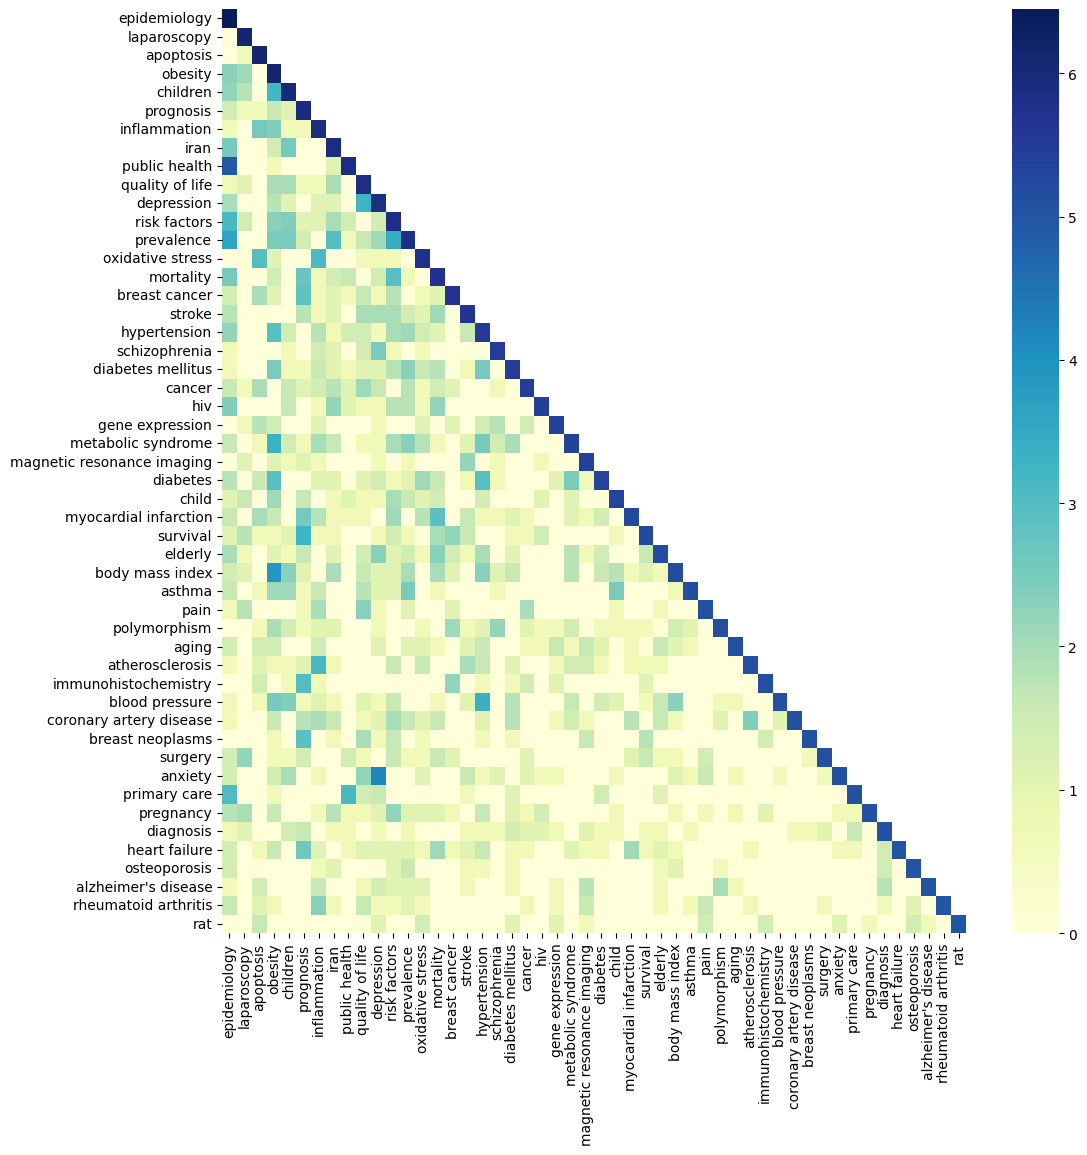

In [26]:
fig, ax = plt.subplots(figsize=(12, 12))
mask = np.triu(np.ones_like(df_adj_top, dtype=bool), k=1)
sns.heatmap(df_adj_top, cmap="YlGnBu", mask=mask,
            xticklabels=True, yticklabels=True, ax=ax)
plt.savefig("keyword_cooccurrence_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

C:\Users\<user>\AppData\Local\Temp\ipykernel_33264\1413589140.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = plt.cm.get_cmap("tab20", len(components))


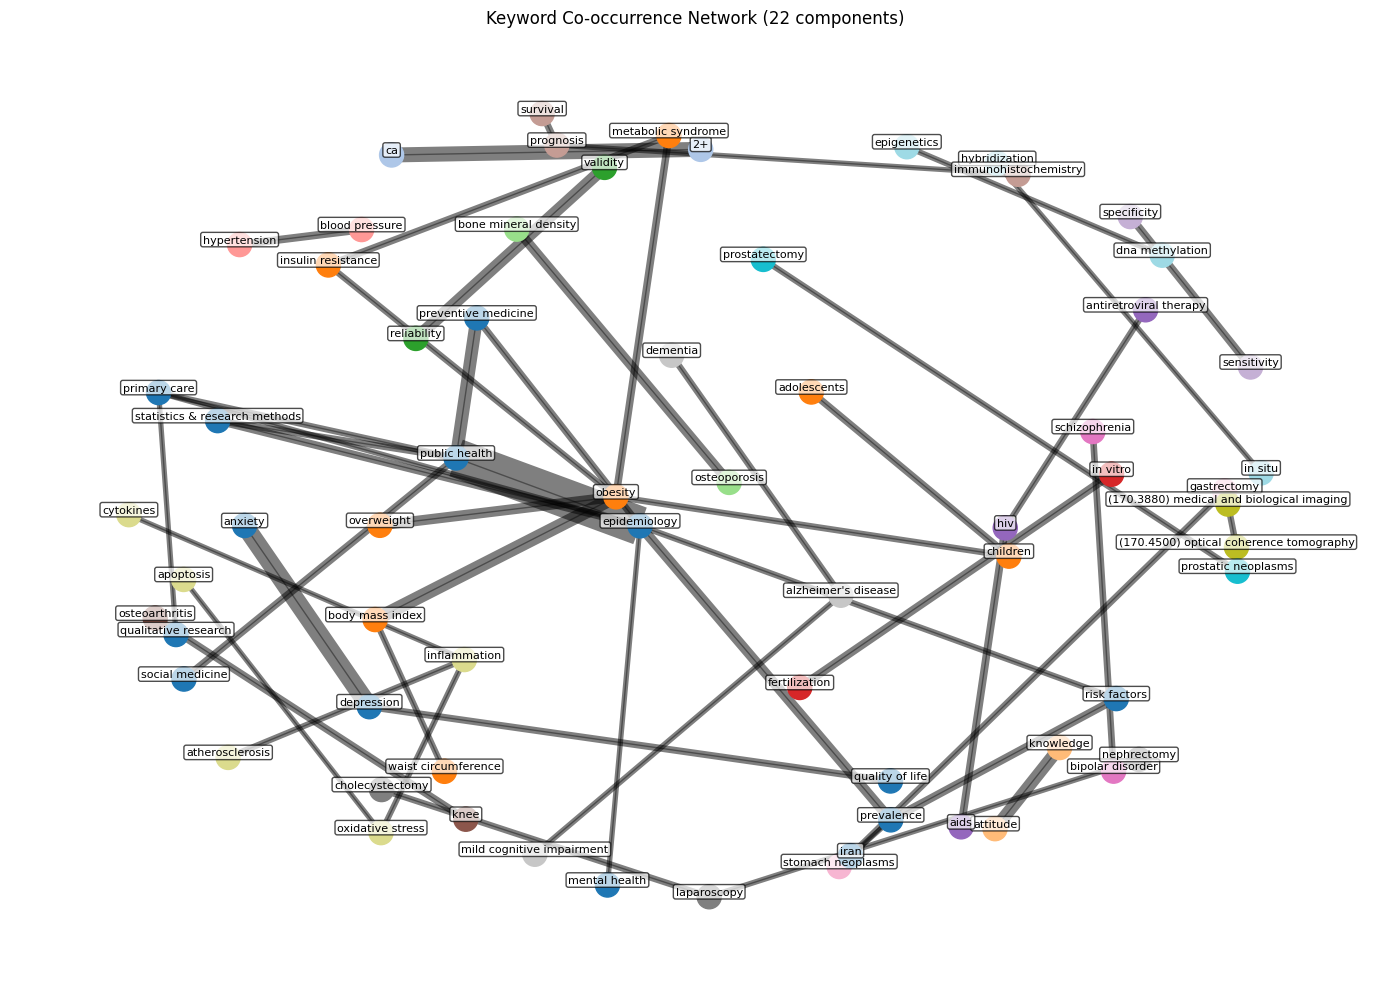

In [27]:
#!pip install networkx
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

G = nx.Graph()
for (kw1, kw2), val in sorted_kw_intersections[:50]:
    if val >= 3:
        G.add_edge(kw1, kw2, weight=val)

# Connected components als Cluster → jede Komponente bekommt eigene Farbe
components = list(nx.connected_components(G))
color_map = plt.cm.get_cmap("tab20", len(components))

node_colors = {}
for i, component in enumerate(components):
    for node in component:
        node_colors[node] = color_map(i)

colors = [node_colors[n] for n in G.nodes()]

fig, ax = plt.subplots(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42, k=2.5,
                       weight="weight")  # Gewicht beeinflusst Abstände


weights = [G[u][v]["weight"] for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=[w*0.2 for w in weights], alpha=0.5, ax=ax)

nx.draw_networkx_nodes(G, pos, node_size=300, node_color=colors, ax=ax)
nx.draw_networkx_edges(G, pos, alpha=0.4, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8,
                        verticalalignment="bottom",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7),
                        ax=ax)

ax.set_title(f"Keyword Co-occurrence Network ({len(components)} components)", fontsize=12)
ax.axis("off")
plt.tight_layout()
plt.savefig("keyword_network.png", dpi=150, bbox_inches="tight")
plt.show()